# 03 – Temporal Trend Analysis

## Urban Heat Island Analysis – Voi Town, Kenya

This notebook investigates temporal changes in Land Surface Temperature (LST), vegetation cover (NDVI), and built-up intensity (NDBI) between 2016 and 2026.

The analysis uses trend estimation, year-to-year changes and linear regression.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load annual indicator statistics
df_stats = pd.read_csv(
    '../outputs/statistics/voi_annual_indicator_statistics.csv'
)

# Display the dataset
display(df_stats)

print("Dataset shape:", df_stats.shape)

,Year,Mean_LST_C,Mean_NDVI,Mean_NDBI
0,2016,41.441006,0.302462,0.108543
1,2017,45.563054,0.263943,0.151019
2,2018,44.718004,0.309786,0.099655
3,2019,44.531500,0.314185,0.113128
4,2020,39.864436,0.396155,0.040007
5,2021,42.428234,0.297537,0.119165
6,2022,45.218097,0.270883,0.138865
7,2023,48.572478,0.235009,0.166130
8,2024,40.109442,0.350381,0.070363
9,2025,40.923833,0.354188,0.068503


Dataset shape: (11, 4)


In [3]:
# Calculate annual changes
df_stats['LST_Change'] = df_stats['Mean_LST_C'].diff()
df_stats['NDVI_Change'] = df_stats['Mean_NDVI'].diff()
df_stats['NDBI_Change'] = df_stats['Mean_NDBI'].diff()

# Display year-to-year changes
display(df_stats.round(4))

,Year,Mean_LST_C,Mean_NDVI,Mean_NDBI,LST_Change,NDVI_Change,NDBI_Change
0,2016,41.4410,0.3025,0.1085,NaN,NaN,NaN
1,2017,45.5631,0.2639,0.1510,4.1220,-0.0385,0.0425
2,2018,44.7180,0.3098,0.0997,-0.8451,0.0458,-0.0514
3,2019,44.5315,0.3142,0.1131,-0.1865,0.0044,0.0135
4,2020,39.8644,0.3962,0.0400,-4.6671,0.0820,-0.0731
5,2021,42.4282,0.2975,0.1192,2.5638,-0.0986,0.0792
6,2022,45.2181,0.2709,0.1389,2.7899,-0.0267,0.0197
7,2023,48.5725,0.2350,0.1661,3.3544,-0.0359,0.0273
8,2024,40.1094,0.3504,0.0704,-8.4630,0.1154,-0.0958
9,2025,40.9238,0.3542,0.0685,0.8144,0.0038,-0.0019


In [4]:
from scipy.stats import linregress

indicators = {
    'Mean_LST_C': 'LST (°C)',
    'Mean_NDVI': 'NDVI',
    'Mean_NDBI': 'NDBI'
}

trend_results = []

for column, label in indicators.items():

    result = linregress(
        df_stats['Year'],
        df_stats[column]
    )

    trend_results.append({
        'Indicator': label,
        'Slope_per_year': result.slope,
        'R_squared': result.rvalue ** 2,
        'P_value': result.pvalue
    })

trend_df = pd.DataFrame(trend_results)

display(trend_df.round(4))

,Indicator,Slope_per_year,R_squared,P_value
0,LST (°C),-0.0193,0.0006,0.9452
1,NDVI,0.0011,0.0058,0.8240
2,NDBI,-0.0016,0.0194,0.6827


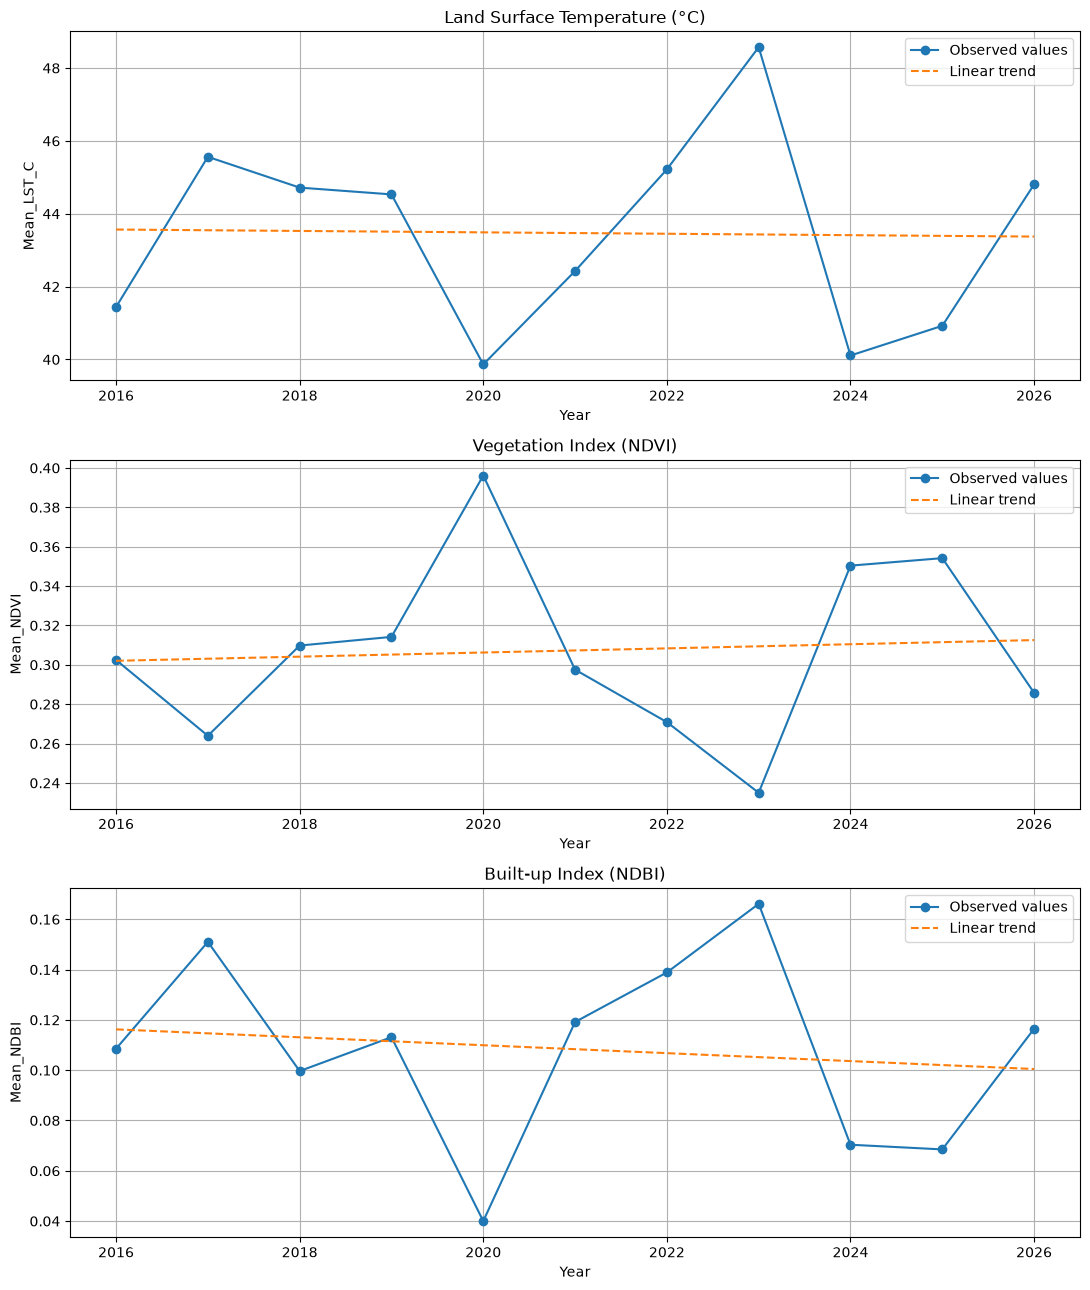

In [5]:
from scipy.stats import linregress

fig, axes = plt.subplots(3, 1, figsize=(11, 13))

indicators = [
    ('Mean_LST_C', 'Land Surface Temperature (°C)'),
    ('Mean_NDVI', 'Vegetation Index (NDVI)'),
    ('Mean_NDBI', 'Built-up Index (NDBI)')
]

for ax, (column, title) in zip(axes, indicators):

    x = df_stats['Year']
    y = df_stats[column]

    result = linregress(x, y)

    predicted = result.intercept + result.slope * x

    ax.plot(x, y, marker='o', label='Observed values')
    ax.plot(x, predicted, linestyle='--', label='Linear trend')

    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.set_ylabel(column)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [9]:
from pathlib import Path

# Ensure output directory exists
output_dir = Path('../outputs/statistics')
output_dir.mkdir(parents=True, exist_ok=True)

# Export regression results
trend_df.to_csv(
    output_dir / 'voi_linear_trend_results.csv',
    index=False
)

# Export year-to-year changes
df_stats.to_csv(
    output_dir / 'voi_temporal_changes.csv',
    index=False
)

print("Temporal analysis results exported successfully!")

Temporal analysis results exported successfully!
